In [ ]:
import os
import urllib.request
from pathlib import Path

import astropy.units as u
import numpy as np
import padre_meddea
from astropy.time import Time, TimeDelta
from astropy.timeseries import TimeSeries
from skyfield.api import load, wgs84
from skyfield.iokit import parse_tle_file
from swxsoc.util.util import record_timeseries
import matplotlib.pyplot as plt
from astropy.visualization import time_support
time_support()
import numpy as np

In [42]:
NORAD_ID = 64559

ts = load.timescale()

celestrack_url = (
    f"https://celestrak.org/NORAD/elements/gp.php?CATNR={NORAD_ID}&FORMAT=TLE"
)
filename = Path(f"20251205_padre.tle")

if not filename.exists():
    urllib.request.urlretrieve(celestrack_url, filename)

In [3]:
with load.open(str(filename)) as f:
    satellites = list(parse_tle_file(f, ts))
satellite = satellites[0]

In [4]:
hit_rate = TimeSeries.read('Hit Rate (TLM1)-data-2025-12-05 09_10_23.csv', format='ascii.csv', time_column='time')

In [5]:
hit_rate.sort()
hit_rate

time,hit_rate
Time,int64
2025-11-28 14:07:28.000,18
2025-11-28 14:07:58.000,23
2025-11-28 14:08:28.000,20
2025-11-28 14:08:58.000,18
2025-11-28 14:09:28.000,33
2025-11-28 14:09:58.000,17
2025-11-28 14:10:28.000,25
2025-11-28 14:10:58.000,20
2025-11-28 14:11:28.000,22


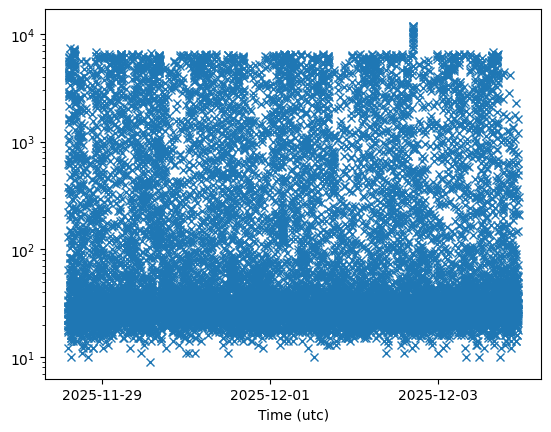

In [6]:
plt.plot(hit_rate.time, hit_rate['hit_rate'], 'x')
plt.yscale('log')

In [36]:
print(f"Hit rate data from {hit_rate.time[0]} to {hit_rate.time[-1]}")

Hit rate data from 2025-11-28 14:07:28.000 to 2025-12-03 22:53:17.000


In [7]:
t = ts.from_astropy(hit_rate.time)


In [8]:

geocentric = satellite.at(t)
lat, lon = wgs84.latlon_of(geocentric)

In [9]:
eph = load("de440s.bsp")  # automatically downloaded if missing
sun = eph["sun"]
sunlit = satellite.at(t).is_sunlit(eph)

ephem_ts = TimeSeries(time=hit_rate.time)
ephem_ts["lon"] = [float(this_lon) for this_lon in lon.degrees]
ephem_ts["lat"] = [float(this_lat) for this_lat in lat.degrees]
ephem_ts["sunlit"] = sunlit


In [10]:
ephem_ts

time,lon,lat,sunlit
Time,float64,float64,bool
2025-11-28 14:07:28.000,-10.166256824476445,33.838941461239806,True
2025-11-28 14:07:58.000,-10.647840227487222,31.992220854405147,True
2025-11-28 14:08:28.000,-11.115445377918697,30.143959778215706,True
2025-11-28 14:08:58.000,-11.570541293351484,28.29428413059191,True
2025-11-28 14:09:28.000,-12.014443604957405,26.443312034815907,True
2025-11-28 14:09:58.000,-12.448336905396413,24.591155280804845,True
2025-11-28 14:10:28.000,-12.873293603816405,22.737920508973055,True
2025-11-28 14:10:58.000,-13.290289935744516,20.88371018271887,True
2025-11-28 14:11:28.000,-13.700219646391368,19.028623386716017,True


In [23]:
# interpolate position onto times of hit rate
x = ephem_ts.time.jd
new_x = hit_rate.time.jd
y1 = ephem_ts['lon']
y2 = ephem_ts['lat']
new_y1 = np.interp(new_x, x, y1)
new_y2 = np.interp(new_x, x, y2)
hit_rate['lon'] = new_y1
hit_rate['lat'] = new_y2


In [11]:
import plotly.express as px

In [39]:
data = {'lon': ephem_ts['lon'], 'lat': ephem_ts['lat']}


In [40]:
fig = px.scatter_geo(data, lat="lat", lon="lon", projection="natural earth", color_continuous_scale=px.colors.sequential.Plasma)
fig.show()

In [41]:
data = {'lon': hit_rate['lon'], 'lat': hit_rate['lat'], 'color':np.log10(hit_rate['hit_rate'])}
fig = px.scatter_geo(data, lat="lat", lon="lon", projection="natural earth", color = 'color', color_continuous_scale=px.colors.sequential.Plasma)
fig.show()


C:\Users\sdchris1\AppData\Local\Temp\1\ipykernel_10212\3968442015.py:1: RuntimeWarning:

divide by zero encountered in log10

